# Predicting Smartphone User Ratings — Final Pipeline (Neat 2)

**Course:** Computer Programming for Data Science and Artificial Intelligence (AIT)
**Group:** Neat 2 — Chatpol Phongyen (st127020), Nyi Htut Oo (st126005)

This notebook runs the **whole final-stage pipeline** and shows every table and figure used in the final report and
slides. The code lives in `src/` so that the demo app (`app/app.py`) uses exactly the same preprocessing and model.

| Step | What it does | Output |
|---|---|---|
| 1 | Load the 3 datasets, clean, group phone families, match datasets (exact name first, then variant key) | `table_match_rates.csv` |
| 2 | Exploratory data analysis | `fig01`–`fig03` |
| 3–4 | Choose the feature set and tune XGBoost on phones released up to 2024 only | `table_feature_set_selection.csv` |
| 5 | Evaluate 4 models under 4 protocols (incl. a Kaggle-style random split) with 95% bootstrap intervals | `table_model_performance.csv`, `fig04` |
| 6 | Agreement between the two rating sources + independence test | `table_independence_test.csv` |
| 7 | Reliability-aware training (review-volume weighting and shrinkage) | `table_reliability_aware_summary.csv`, `fig05` |
| 8 | Error by review volume | `fig06` |
| 9 | Ordinal comparison (3 rating levels) | `table_ordinal_comparison.csv` |
| 10 | Interpretability (SHAP, linear coefficients) | `fig07` |
| 11 | Complexity (training time, prediction time, model size) | `table_complexity.csv` |
| 12 | Train and save the final model for the app | `models/final_model.joblib` |

**How to run:** install the libraries once (`pip install -r requirements.txt`), then **Kernel → Restart & Run All**.
The three datasets are in `data/`. Random seed = 42 everywhere.

In [1]:
import json, platform
import numpy as np, pandas as pd
from IPython.display import Image, display
import sklearn, xgboost, scipy, matplotlib
from src import models as M, pipeline as P

np.random.seed(M.RANDOM_STATE)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
for k, v in {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "scipy": scipy.__version__,
             "matplotlib": matplotlib.__version__}.items():
    print(f"{k:13s} {v}")

python        3.13.16
pandas        3.0.1
numpy         2.4.3
scikit-learn  1.9.0
xgboost       3.4.1
scipy         1.18.1
matplotlib    3.11.1


## 1. Data, cleaning and matching
Dataset 1 is always the left table; no rated phone is dropped and no unrated phone is added.
**New in the final stage:** an **exact-name step** runs before the progress-stage variant-key rule. The variant key
removes 4G/5G and RAM/storage words, so phones such as *Galaxy A14* and *Galaxy A14 5G* became ambiguous and were
left unmatched. The manual audit at the progress stage found 69 such missed matches.

**Fix in the final stage:** MySmartPrice writes its largest review counts in the Indian unit *lakh*
(e.g. "1.5L Ratings" = 150,000). The progress-stage parser ignored "L" and read this as 1.5 reviews, so some of
the most-reviewed phones were counted as having fewer than 50 reviews. The last table shows the effect.

In [2]:
D = P.stage_data()
work = D["work"]
print(f"Working sample: {len(work):,} rated phones, {work['family'].nunique()} phone families, {work['brand'].nunique()} brands")
display(D["match_rates"])
display(D["steps"])
display(D["recovery"])
D["count_fix"]

Working sample: 1,597 rated phones, 860 phone families, 28 brands


,Overall,2022,2023,2024,2025,2026
"D1 → D2, progress rule (variant key)",63.1,92.5,92.8,95.2,8.9,0.8
"D1 → D2, final rule (exact name, then key)",66.6,99.4,98.4,98.6,8.9,0.8
"D1 → D3, progress rule (variant key)",32.3,27.5,39.6,49.4,31.7,1.6
"D1 → D3, final rule (exact name, then key)",37.0,31.7,42.5,57.2,37.8,1.6


,Join,Step,matched,ambiguous
0,Dataset 1 → Dataset 2,exact,1303,0
1,Dataset 1 → Dataset 2,key,9,4
2,Dataset 1 → Dataset 3,exact,443,3
3,Dataset 1 → Dataset 3,key,286,76


d2_matched,matched now,unmatched now
should_match,,
no partner (audit),0,15
should match (audit),69,0


,Progress parser,Fixed parser
Fewer than 50,97,41
50 to 500,120,120
"500 to 5,000",329,329
"More than 5,000",426,482
Phones whose count uses 'L' (lakh),56,56


## 2. Exploratory data analysis

,value
Phones,1597.00
Phone families,860.00
Brands,28.00
Rating mean,4.24
Rating median,4.30
Rating SD,0.31
Rating skewness,-3.14
IQR outliers in rating,66.00


,missing %
refresh_hz,58.2
pixel_ppi,55.9
chipset_vendor,55.8
antutu,43.6
charging_w,2.4
spec_score,1.4
storage_gb,0.6
ram_gb,0.4
price_inr,0.1
is_amoled,0.1


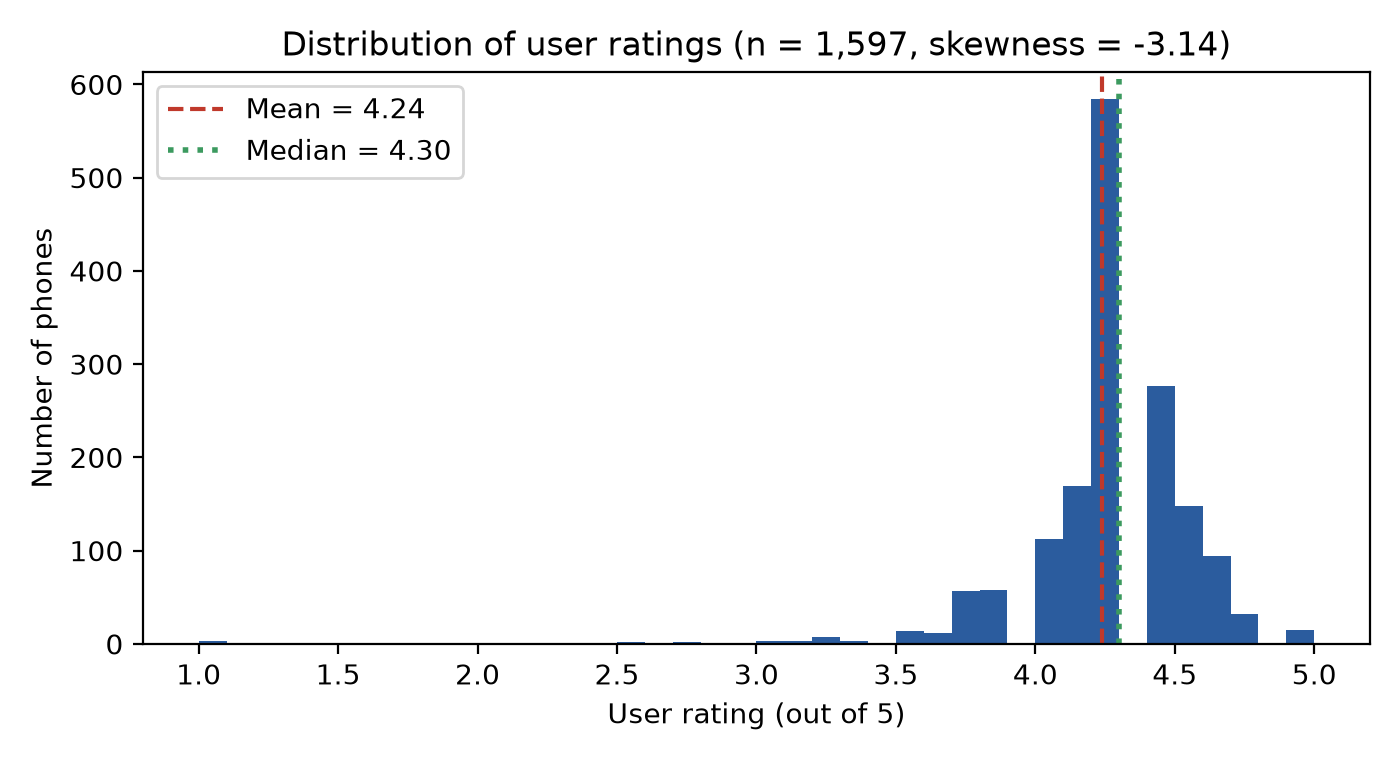

,Pearson r,RF importance
pixel_ppi,0.415,0.028
spec_score,0.375,0.200
antutu,0.318,0.128
price_inr,0.281,0.209
charging_w,0.266,0.058
ram_gb,0.265,0.033
storage_gb,0.221,0.027
is_amoled,0.205,0.008
front_mp,0.197,0.050
refresh_hz,0.190,0.008


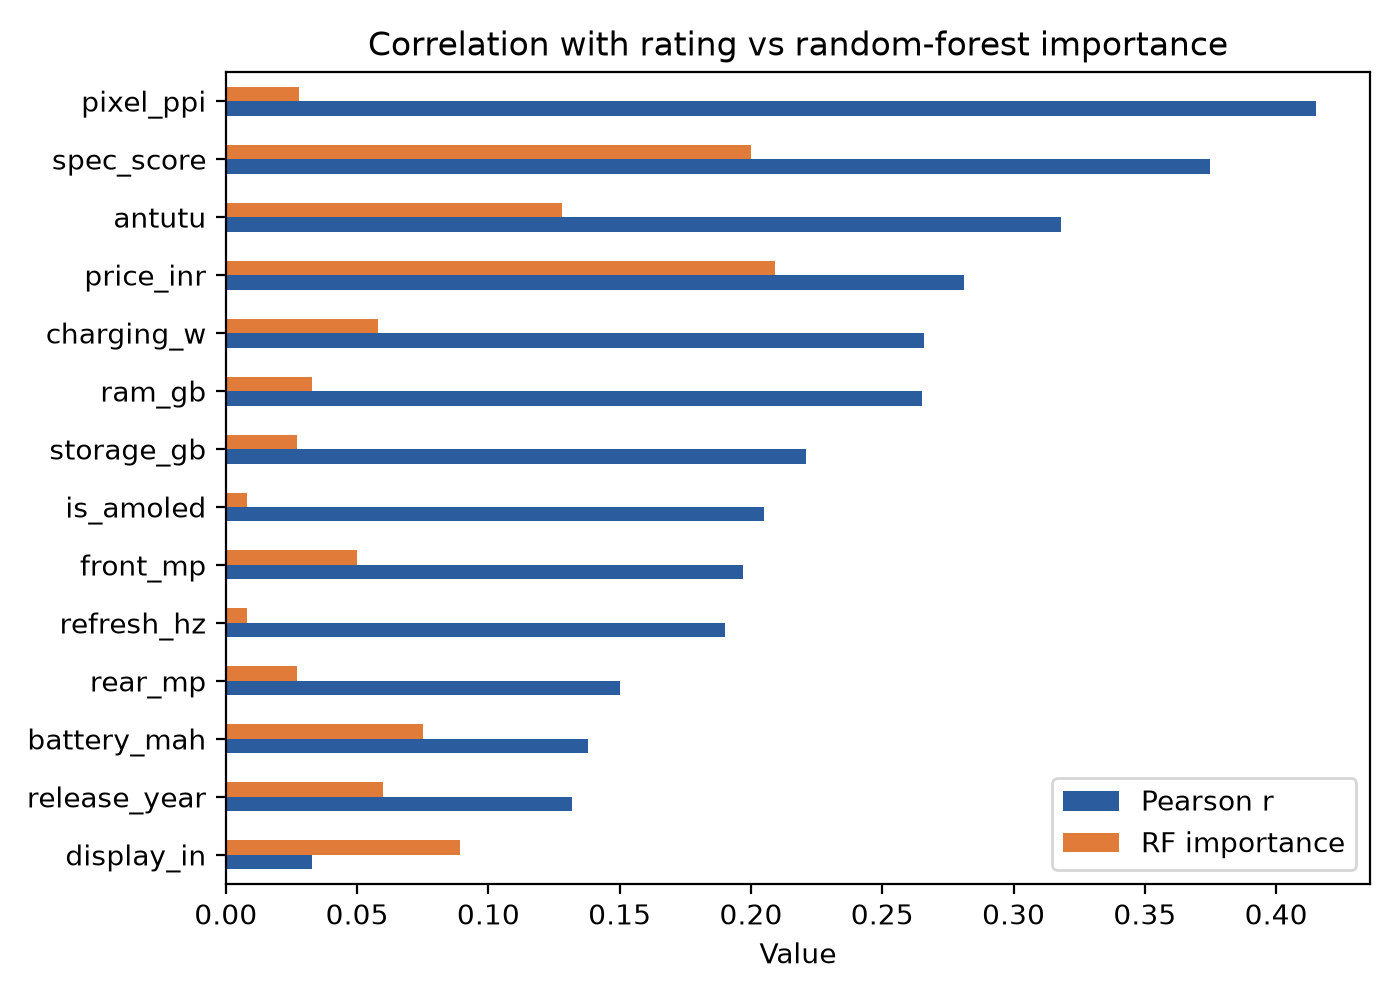

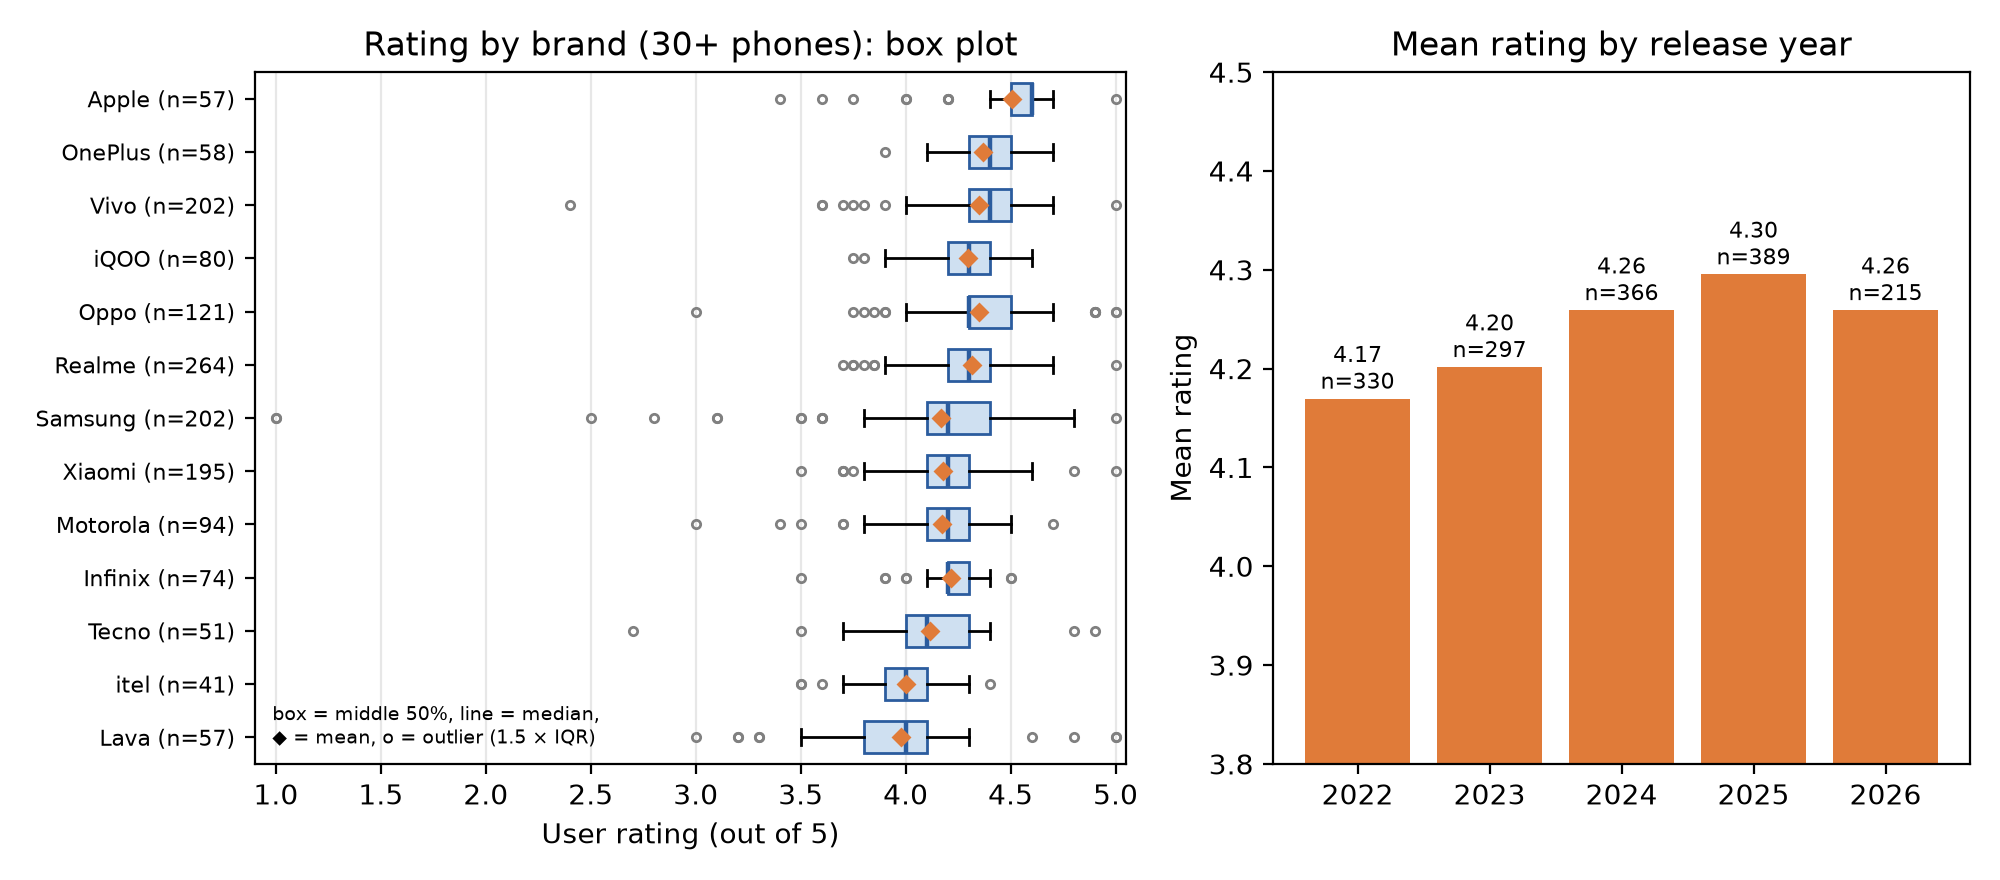

In [3]:
EDA = P.stage_eda(work)
display(pd.Series(EDA["eda"]).to_frame("value"))
display(EDA["missing"].to_frame("missing %"))
display(Image("figures/fig01_rating_distribution.png", width=650))
display(EDA["corr_imp"])
display(Image("figures/fig02_corr_vs_importance.png", width=650))
display(Image("figures/fig03_rating_by_brand_year.png", width=900))

## 3–4. Feature set and XGBoost tuning
Four feature sets are compared with grouped 5-fold CV on **phones released up to 2024 only**, so the 2025–26 test
phones are never used for any choice. The set with the lowest average MAE over the three models is kept.

In [4]:
F = P.stage_features(work)
num, cat = M.FEATURE_SETS[F["chosen"]]
xgb_params = F["xgb_params"]
print("Chosen feature set:", F["chosen"], "| XGBoost settings:", xgb_params)
F["feature_sets"].round(4)

Chosen feature set: C: + Dataset 3 features | XGBoost settings: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 600}


,Feature set,Predictors,XGBoost,Linear Regression,Random Forest,Average of 3 models,XGBoost settings,Chosen
0,A: progress-stage features,13,0.1245,0.1292,0.1254,0.1263,"{""learning_rate"": 0.03, ""max_depth"": 3, ""n_est...",
1,B: without AnTuTu,12,0.1240,0.1291,0.1267,0.1266,"{""learning_rate"": 0.03, ""max_depth"": 6, ""n_est...",
2,C: + Dataset 3 features,16,0.1211,0.1289,0.1244,0.1248,"{""learning_rate"": 0.03, ""max_depth"": 4, ""n_est...",yes
3,"D: + Dataset 3, without AnTuTu",15,0.1206,0.1289,0.1258,0.1251,"{""learning_rate"": 0.03, ""max_depth"": 6, ""n_est...",


## 5. Model evaluation
**Baseline:** a dummy model that always predicts the average training rating.
**Protocols:** a Kaggle-style random 5-fold split (for comparison only), grouped 5-fold CV (phone families kept
together), leave-one-brand-out, and the future-year split (train ≤ 2024, test 2025–26).
Intervals are 95% bootstrap intervals (2,000 resamples of phone families).

,Protocol,Model,Test phones,MAE,RMSE,R2,MAE low,MAE high,R2 low,R2 high
0,Random 5-fold (Kaggle style),Dummy (mean),1597,0.204,0.311,-0.003,0.190,0.218,-0.009,-0.002
1,Grouped 5-fold,Dummy (mean),1597,0.203,0.310,-0.002,0.189,0.218,-0.008,-0.000
2,Leave-one-brand-out,Dummy (mean),1597,0.207,0.314,-0.024,0.193,0.222,-0.034,-0.019
3,Future-year (≤2024 → 2025–26),Dummy (mean),604,0.256,0.388,-0.034,0.232,0.283,-0.108,-0.006
4,Random 5-fold (Kaggle style),Linear Regression,1597,0.154,0.271,0.234,0.143,0.167,0.158,0.327
5,Grouped 5-fold,Linear Regression,1597,0.157,0.272,0.229,0.146,0.170,0.158,0.316
6,Leave-one-brand-out,Linear Regression,1597,0.179,0.288,0.135,0.167,0.192,0.081,0.200
7,Future-year (≤2024 → 2025–26),Linear Regression,604,0.222,0.383,-0.006,0.197,0.250,-0.120,0.079
8,Random 5-fold (Kaggle style),Random Forest,1597,0.145,0.273,0.226,0.133,0.158,0.076,0.362
9,Grouped 5-fold,Random Forest,1597,0.155,0.273,0.225,0.143,0.168,0.032,0.382


,Random 5-fold (Kaggle style),Grouped 5-fold,Leave-one-brand-out,Future-year (≤2024 → 2025–26)
Model,,,,
Dummy (mean),0.204,0.203,0.207,0.256
Linear Regression,0.154,0.157,0.179,0.222
Random Forest,0.145,0.155,0.181,0.211
XGBoost (tuned),0.146,0.153,0.177,0.205


,Random 5-fold (Kaggle style),Grouped 5-fold,Leave-one-brand-out,Future-year (≤2024 → 2025–26)
Model,,,,
Dummy (mean),-0.003,-0.002,-0.024,-0.034
Linear Regression,0.234,0.229,0.135,-0.006
Random Forest,0.226,0.225,0.066,0.098
XGBoost (tuned),0.216,0.253,0.109,0.116


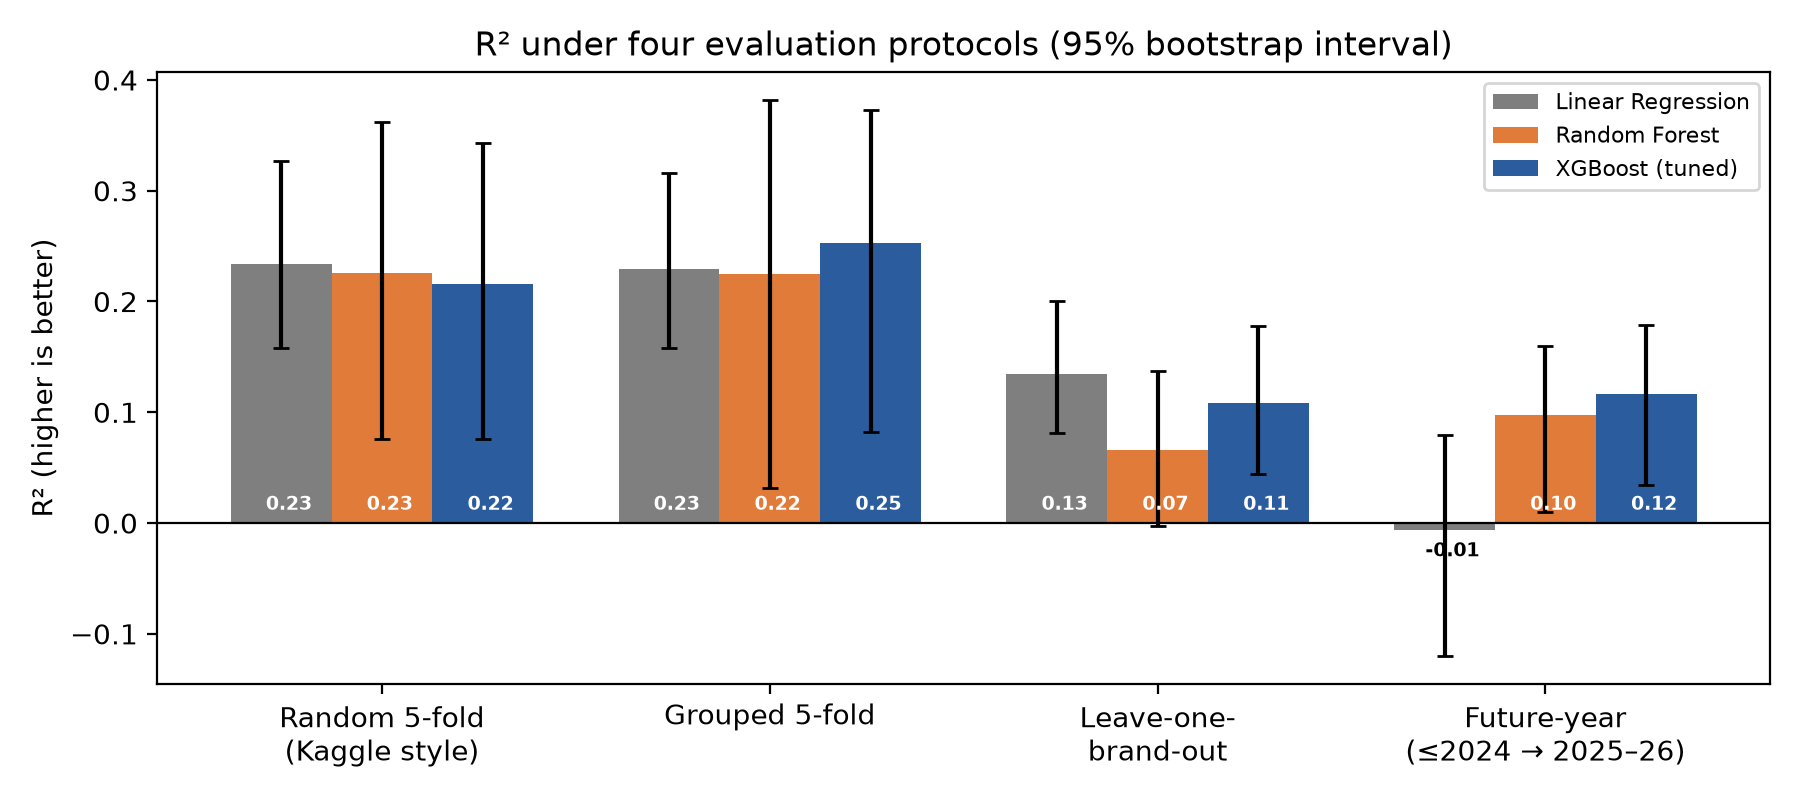

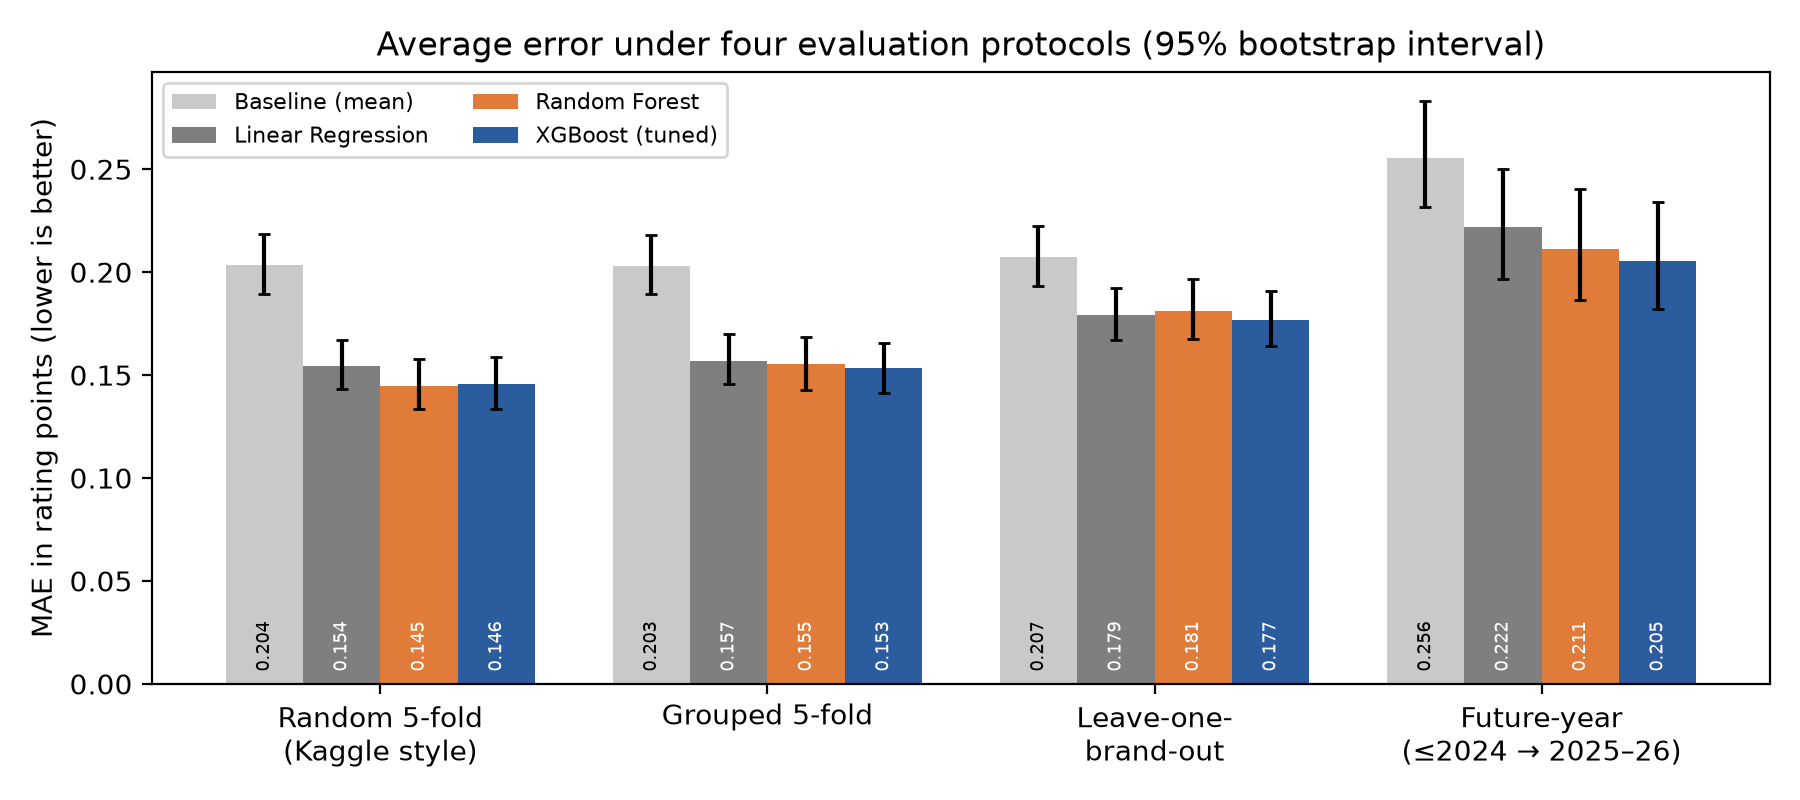

In [5]:
EV = P.stage_evaluate(work, num, cat, xgb_params)
display(EV["table"].round(3))
display(pd.read_csv("results/table_mae_by_protocol.csv", index_col=0))
display(pd.read_csv("results/table_r2_by_protocol.csv", index_col=0))
display(Image("figures/fig04_r2_by_protocol.png", width=850))
Image("figures/fig04b_mae_by_protocol.png", width=850)

### 5b. Is the difference real?
**Feature-set ablation:** XGBoost with each feature set under every protocol.
**Paired comparison:** change in MAE of XGBoost against each other model on the same test phones, with a 95%
bootstrap interval (negative = XGBoost is better).

In [6]:
display(P.stage_ablation(work, F["feature_sets"], EV["splits"]).round(4))
P.stage_paired_models(work, EV["preds"], EV["splits"])

Protocol,Random 5-fold (Kaggle style),Grouped 5-fold,Leave-one-brand-out,Future-year (≤2024 → 2025–26)
Feature set,,,,
A: progress-stage features,0.1480,0.1547,0.1771,0.1957
B: without AnTuTu,0.1457,0.1534,0.1757,0.1980
C: + Dataset 3 features,0.1458,0.1533,0.1767,0.2053
"D: + Dataset 3, without AnTuTu",0.1431,0.1519,0.1740,0.2083


,Protocol,XGBoost vs,Other MAE,XGBoost MAE,Difference,Change (%),95% CI low,95% CI high,XGBoost significantly better
0,Random 5-fold (Kaggle style),Dummy (mean),0.2035,0.1458,-0.0578,-28.3814,-0.0681,-0.0473,yes
1,Random 5-fold (Kaggle style),Linear Regression,0.1543,0.1458,-0.0086,-5.5436,-0.0144,-0.0028,yes
2,Random 5-fold (Kaggle style),Random Forest,0.1449,0.1458,0.0009,0.6063,-0.0031,0.0051,no
3,Grouped 5-fold,Dummy (mean),0.2031,0.1533,-0.0498,-24.5211,-0.0598,-0.0391,yes
4,Grouped 5-fold,Linear Regression,0.1569,0.1533,-0.0036,-2.2921,-0.0099,0.0031,no
5,Grouped 5-fold,Random Forest,0.1554,0.1533,-0.0021,-1.3613,-0.0071,0.0030,no
6,Leave-one-brand-out,Dummy (mean),0.2073,0.1767,-0.0306,-14.7408,-0.0381,-0.0224,yes
7,Leave-one-brand-out,Linear Regression,0.1791,0.1767,-0.0024,-1.3314,-0.0079,0.0037,no
8,Leave-one-brand-out,Random Forest,0.1810,0.1767,-0.0042,-2.3432,-0.0084,-0.0003,yes
9,Future-year (≤2024 → 2025–26),Dummy (mean),0.2557,0.2053,-0.0504,-19.7110,-0.0642,-0.0363,yes


## 6. Agreement between the two rating sources (with the new matching)
If the two sites were independent, phones with few reviews should almost never show the same rating.

In [7]:
AG = P.stage_agreement(work)
display(pd.Series(AG["agreement"]).to_frame("value"))
AG["independence"]

,value
Phones rated in both sources,972
Pearson r,0.885
Mean absolute difference,0.045
Identical ratings (%),73.4
Independence test z,-1.3
Independence test p,1.8e-01
Strict pairs (RAM/storage agree),965
Strict pairs Pearson r,0.885


,Phones,Observed,Expected,Expected_sigma_1_3,Expected_sigma_0_7,z,p (two-sided)
band,,,,,,,
Fewer than 50,41,43.9,12.0,10.4,15.6,6.4,2.0e-10
50 to 500,120,63.3,37.2,29.7,48.7,6.1,1.3e-09
"500 to 5,000",329,71.4,71.7,64.2,80.0,-0.1,9.2e-01
"More than 5,000",482,79.7,91.9,89.5,94.3,-10.0,2.2e-23
All phones,972,73.4,74.9,70.2,80.5,-1.3,1.8e-01


## 7. Reliability-aware training
Weighting: `w = n / (n + m)`. Shrinkage: `y* = λ·y + (1 − λ)·brand mean`, `λ = n / (n + k)`.
`m` and `k` are chosen from 30, 100, 300 on phones up to 2024. Paired bootstrap of the change in MAE
(`*` = 95% interval excludes zero).

Chosen m / k: {('Linear Regression', 'shrink'): 300, ('Linear Regression', 'weight'): 300, ('Random Forest', 'shrink'): 300, ('Random Forest', 'weight'): 300, ('XGBoost (tuned)', 'shrink'): 100, ('XGBoost (tuned)', 'weight'): 30}


,Phones,With review count,Reliable (500+)
release_year,,,
2022.0,330,329,311
2023.0,297,296,265
2024.0,366,325,226
2025.0,389,20,9
2026.0,215,2,0
All,1597,972,811


Model                                   Linear Regression Random Forest XGBoost (tuned)
Grouped 5-fold                Weighted               +0.2          +1.1            +0.7
                              Shrinkage              -0.0          -0.6            -0.4
Leave-one-brand-out           Weighted               +0.4          -0.1            -0.1
                              Shrinkage              +1.2          -1.2            +0.7
Future-year (≤2024 → 2025–26) Weighted              -3.3*         -6.2*            -0.7
                              Shrinkage             -8.6*          -2.0            +1.2

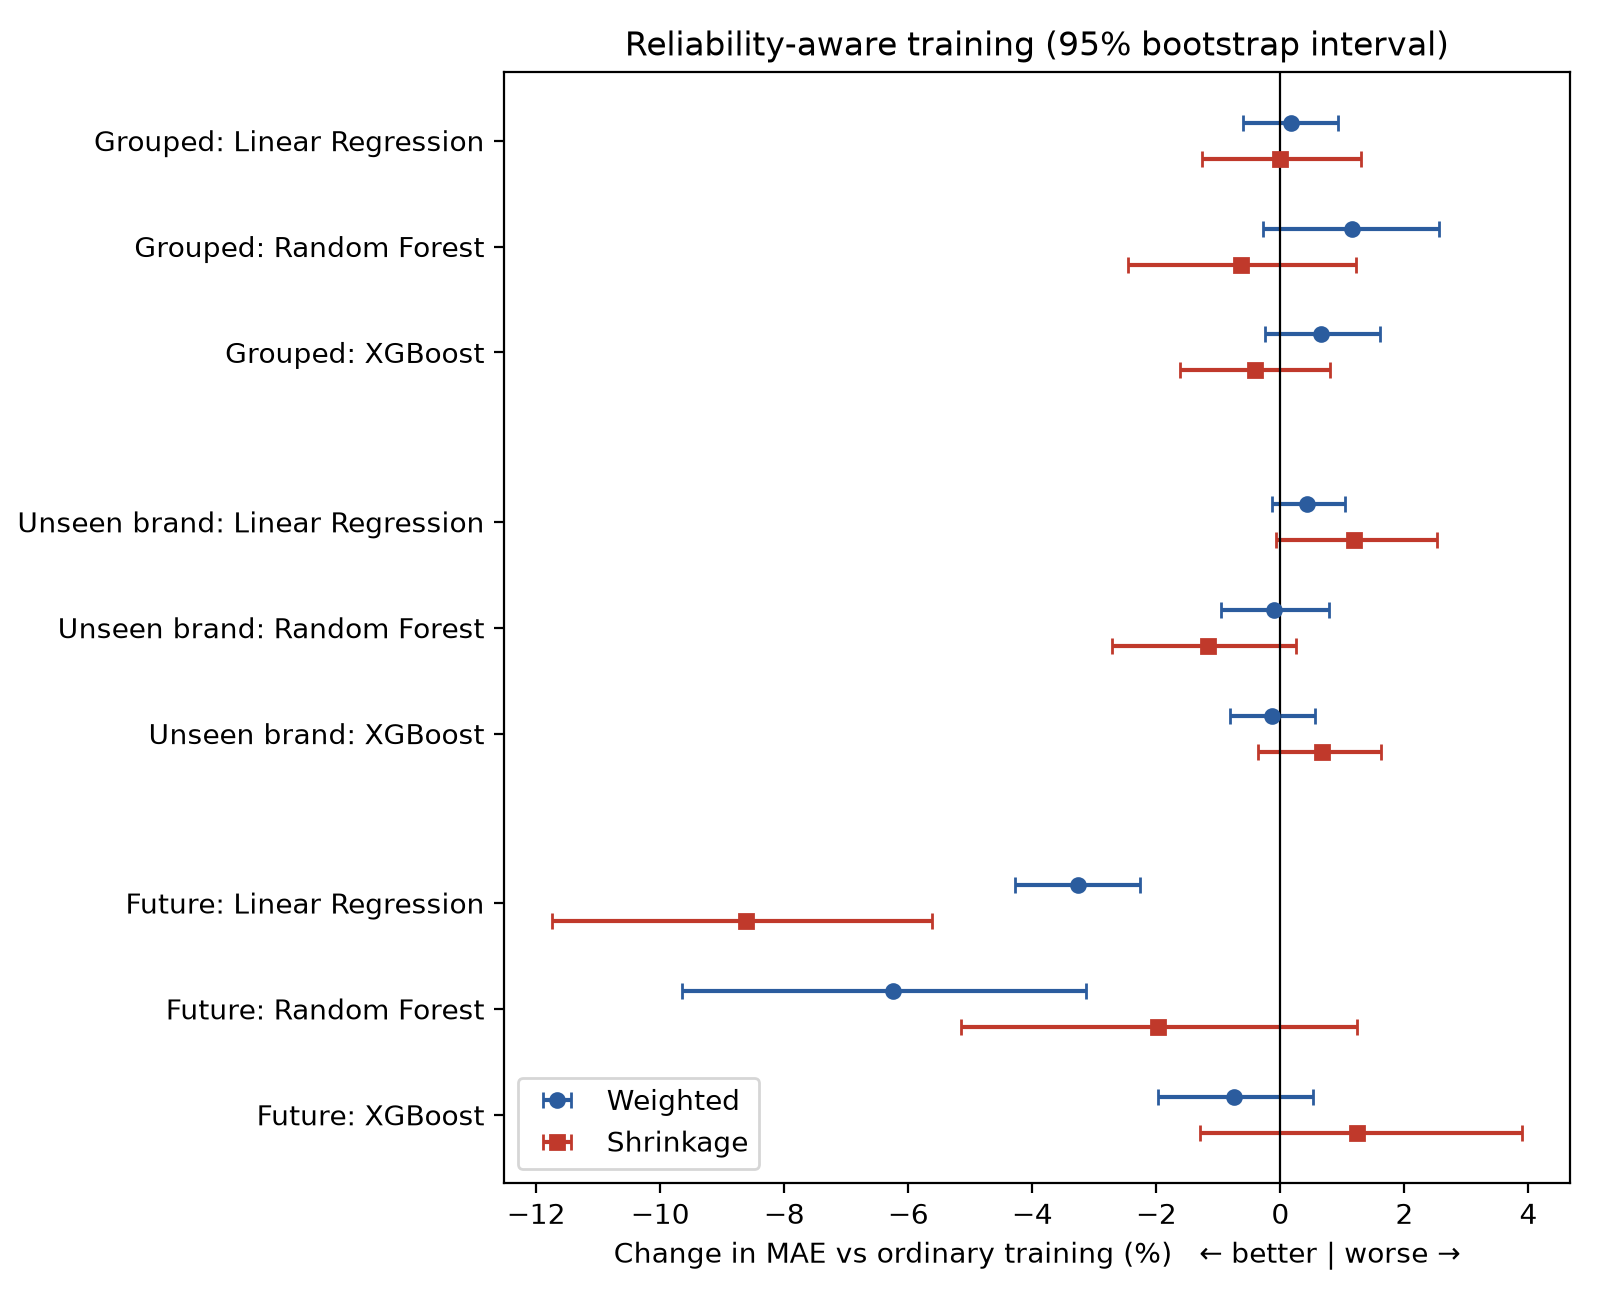

In [8]:
RA = P.stage_reliability(work, num, cat, xgb_params, EV["splits"])
print("Chosen m / k:", RA["chosen"])
display(RA["coverage"])
display(RA["summary"])
Image("figures/fig05_reliability_aware.png", width=750)

## 8. Error by review volume

,Phones,Rating SD,MAE Linear Regression,MAE Random Forest,MAE XGBoost (tuned)
Fewer than 50,41,0.362,0.237,0.247,0.222
50 to 500,120,0.408,0.189,0.186,0.169
"500 to 5,000",329,0.256,0.121,0.131,0.123
"More than 5,000",482,0.147,0.095,0.092,0.090
No review count,625,0.388,0.212,0.206,0.211


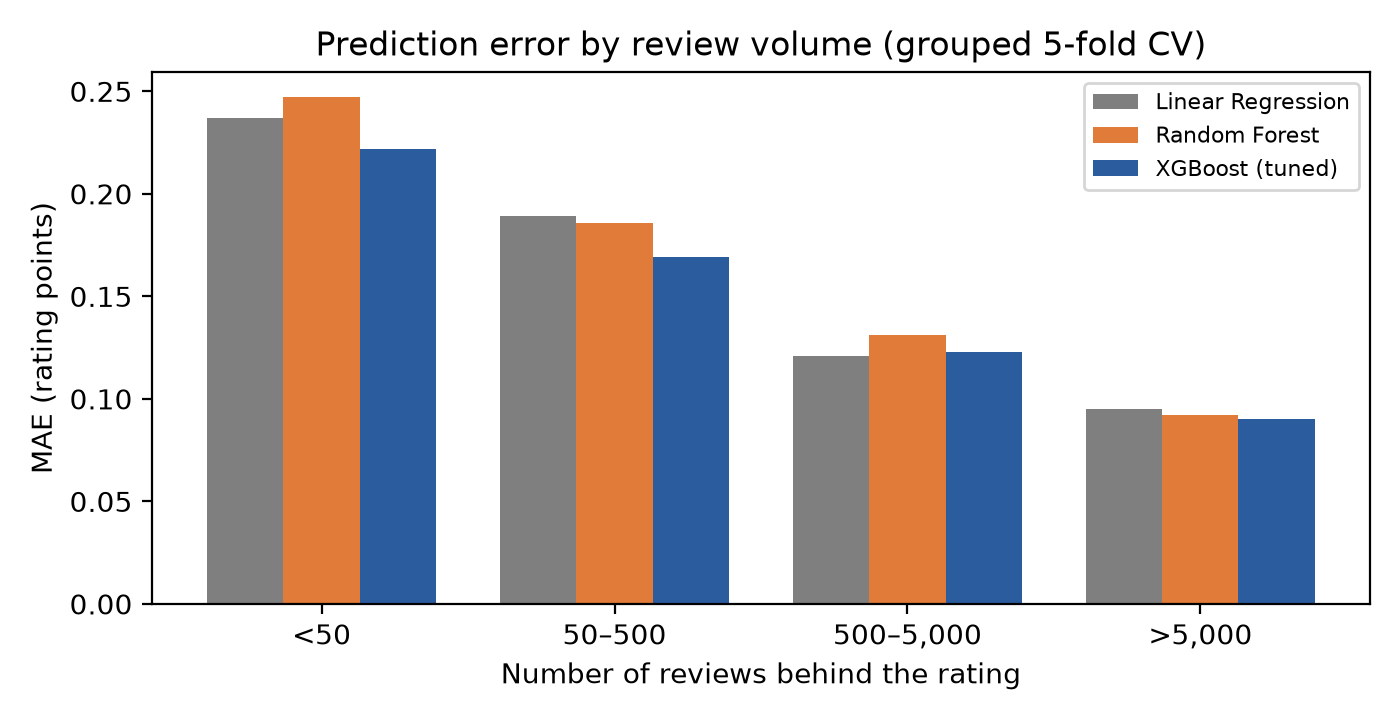

In [9]:
display(P.stage_error_by_volume(work, EV["preds"]))
Image("figures/fig06_error_by_review_volume.png", width=650)

## 9. Ordinal comparison (secondary task)
Three levels: **Low < 4.0**, **Medium 4.0–4.4**, **High ≥ 4.5** (from the rating distribution).
Metrics: quadratic weighted kappa (QWK, higher is better), MAE in levels and accuracy.

In [10]:
OR = P.stage_ordinal(work, num, cat, EV["preds"], EV["splits"])
display(pd.read_csv("results/table_ordinal_levels.csv"))
OR["table"].round(3)

,Level,Phones,Share (%)
0,Low (<4.0),166,10.4
1,Medium (4.0–4.4),1142,71.5
2,High (≥4.5),289,18.1


,Protocol,Model,QWK,MAE (levels),Accuracy,Two levels off (%)
0,Grouped 5-fold,"Random Forest classifier (baseline, ignores or...",0.518,0.208,0.802,1.002
1,Grouped 5-fold,Ordinal logistic regression,0.375,0.239,0.766,0.501
2,Grouped 5-fold,"XGBoost regression, then cut into levels",0.368,0.264,0.741,0.564
3,Grouped 5-fold,Always 'Medium' (majority level),0.000,0.285,0.715,0.000
4,Leave-one-brand-out,"Random Forest classifier (baseline, ignores or...",0.319,0.259,0.751,0.939
5,Leave-one-brand-out,Ordinal logistic regression,0.193,0.265,0.740,0.501
6,Leave-one-brand-out,"XGBoost regression, then cut into levels",0.177,0.279,0.728,0.626
7,Leave-one-brand-out,Always 'Medium' (majority level),0.000,0.285,0.715,0.000
8,Future-year (≤2024 → 2025–26),"Random Forest classifier (baseline, ignores or...",0.316,0.351,0.664,1.490
9,Future-year (≤2024 → 2025–26),Ordinal logistic regression,0.251,0.376,0.641,1.656


## 10. Interpretability

,mean |SHAP|
spec_score,0.0717
brand,0.0610
price_inr,0.0321
battery_mah,0.0245
antutu,0.0203
charging_w,0.0192
display_in,0.0153
ram_gb,0.0137
refresh_hz,0.0123
front_mp,0.0113


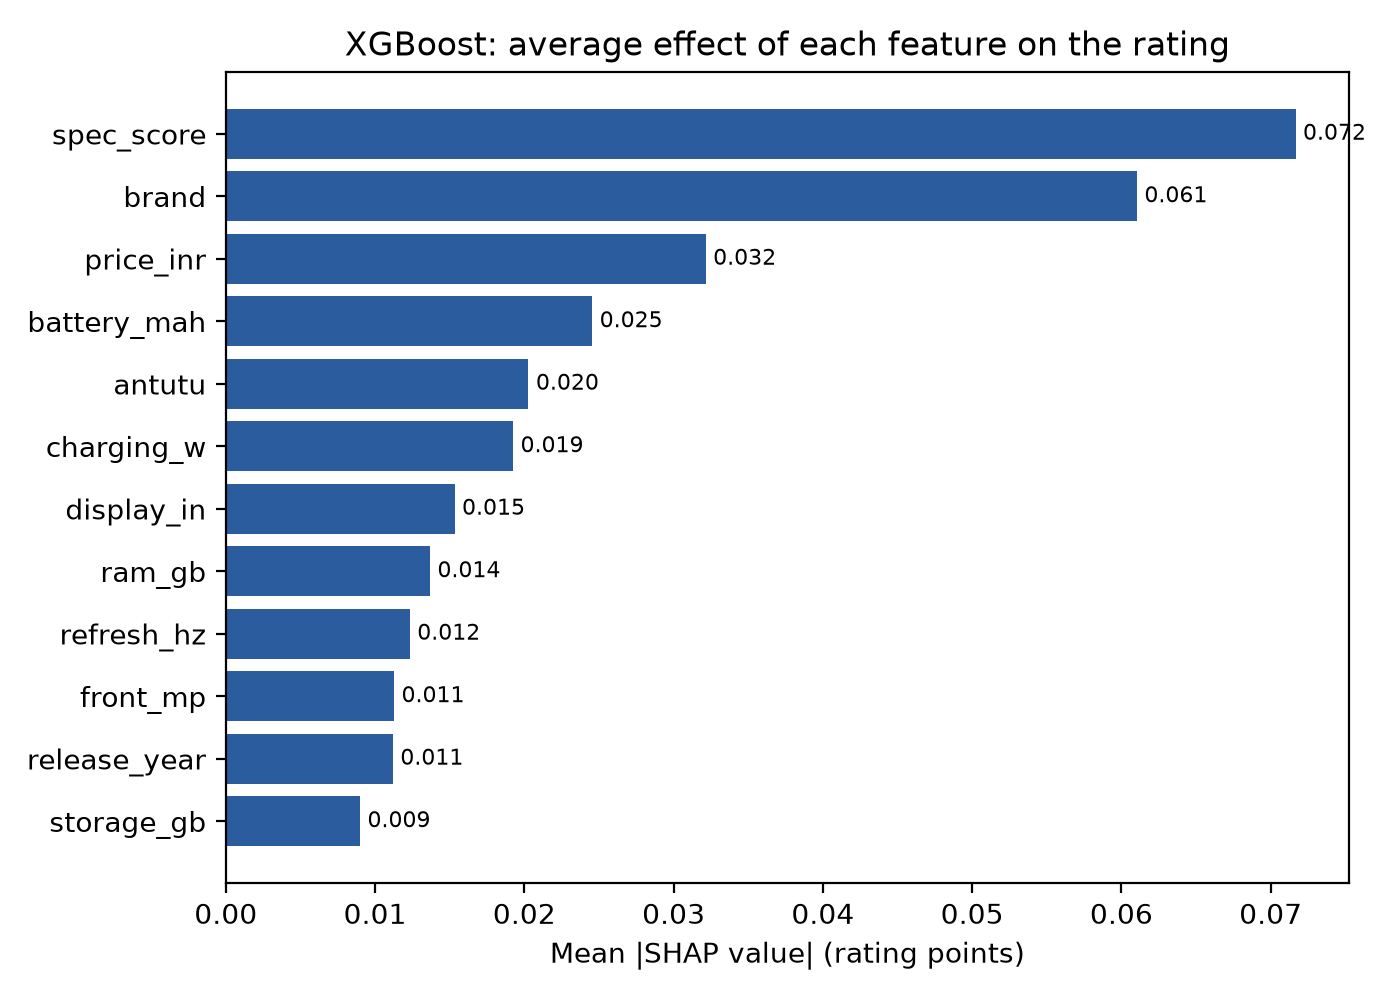

,standardised coefficient
spec_score,0.0808
brand_Samsung,-0.0390
missingindicator_spec_score,-0.0376
brand_infrequent_sklearn,-0.0372
brand_Vivo,0.0345
brand_Nokia,-0.0323
battery_mah,0.0316
brand_Realme,0.0290
price_inr,0.0289
missingindicator_refresh_hz,-0.0286


In [11]:
IN = P.stage_interpret(work, num, cat, xgb_params)
display(IN["shap_importance"].round(4).to_frame("mean |SHAP|"))
display(Image("figures/fig07_shap_importance.png", width=650))
IN["lr_coef"].head(15).round(4).to_frame("standardised coefficient")

## 11. Complexity

In [12]:
P.stage_complexity(work, num, cat, xgb_params)

,Model,Training time on all phones (s),"Prediction time per 1,000 phones (ms)",Saved model size (KB),Size of the model
0,Dummy (mean),0.00,0.01,0.8,1 (the mean)
1,Linear Regression,0.02,1.76,8.0,48 coefficients
2,Random Forest,1.87,26.61,36983.6,"400 trees, 523,718 nodes"
3,XGBoost (tuned),0.19,6.54,867.8,"600 trees, depth ≤ 4"


## 12. Final model (used by the demo app)
Trained on all phones and saved to `models/`. Run the app with `streamlit run app/app.py`.

In [13]:
model, meta = P.stage_final_model(work, num, cat, xgb_params)
{k: meta[k] for k in ["model", "numeric", "categorical", "xgb_params", "trained_on_phones"]}

{'model': 'XGBoost (tuned)',
 'numeric': ['price_inr',
  'ram_gb',
  'storage_gb',
  'battery_mah',
  'charging_w',
  'display_in',
  'is_amoled',
  'rear_mp',
  'front_mp',
  'spec_score',
  'antutu',
  'release_year',
  'refresh_hz',
  'pixel_ppi'],
 'categorical': ['brand', 'chipset_vendor'],
 'xgb_params': {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 600},
 'trained_on_phones': 1597}